In [25]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliotecas carregadas com sucesso!")


Bibliotecas carregadas com sucesso!


In [26]:
conexao = sqlite3.connect("dados_vendas.db")
cursor = conexao.cursor()

cursor.execute("DROP TABLE IF EXISTS vendas1")

cursor.execute("""
CREATE TABLE vendas1 (
    id_venda INTEGER PRIMARY KEY AUTOINCREMENT,
    data_venda DATE,
    produto TEXT,
    categoria TEXT,
    valor_venda REAL
)
""")

dados_vendas = [
    ("2023-01-01", "Produto A", "Eletrônicos", 1500.00),
    ("2023-01-05", "Produto B", "Roupas", 350.00),
    ("2023-02-10", "Produto C", "Eletrônicos", 1200.00),
    ("2023-03-15", "Produto D", "Livros", 200.00),
    ("2023-03-20", "Produto E", "Eletrônicos", 800.00),
    ("2023-04-02", "Produto F", "Roupas", 400.00),
    ("2023-05-05", "Produto G", "Livros", 150.00),
    ("2023-06-10", "Produto H", "Eletrônicos", 1000.00),
    ("2023-07-20", "Produto I", "Roupas", 600.00),
    ("2023-08-25", "Produto J", "Eletrônicos", 700.00),
    ("2023-09-30", "Produto K", "Livros", 300.00),
    ("2023-10-05", "Produto L", "Roupas", 450.00),
    ("2023-11-15", "Produto M", "Eletrônicos", 900.00),
    ("2023-12-20", "Produto N", "Livros", 250.00)
]

cursor.executemany("""
INSERT INTO vendas1
(data_venda, produto, categoria, valor_venda)
VALUES (?, ?, ?, ?)
""", dados_vendas)

conexao.commit()

print("Banco de dados criado com sucesso!")
print(f"Quantidade de vendas cadastradas: {len(dados_vendas)}")

Banco de dados criado com sucesso!
Quantidade de vendas cadastradas: 14


In [27]:
df_vendas = pd.read_sql_query(
    "SELECT * FROM vendas1",
    conexao
)

df_vendas["data_venda"] = pd.to_datetime(
    df_vendas["data_venda"]
)

df_vendas["mes_numero"] = df_vendas["data_venda"].dt.month
df_vendas["mes"] = df_vendas["data_venda"].dt.strftime("%b")

print("DADOS CARREGADOS")
display(df_vendas)

print("\nTIPOS DOS DADOS")
print(df_vendas.dtypes)

print("\nVALORES AUSENTES")
print(df_vendas.isnull().sum())

print("\nREGISTROS DUPLICADOS")
print(df_vendas.duplicated().sum())

DADOS CARREGADOS


,id_venda,data_venda,produto,categoria,valor_venda,mes_numero,mes
0,1,2023-01-01,Produto A,Eletrônicos,1500.0,1,Jan
1,2,2023-01-05,Produto B,Roupas,350.0,1,Jan
2,3,2023-02-10,Produto C,Eletrônicos,1200.0,2,Feb
3,4,2023-03-15,Produto D,Livros,200.0,3,Mar
4,5,2023-03-20,Produto E,Eletrônicos,800.0,3,Mar
5,6,2023-04-02,Produto F,Roupas,400.0,4,Apr
6,7,2023-05-05,Produto G,Livros,150.0,5,May
7,8,2023-06-10,Produto H,Eletrônicos,1000.0,6,Jun
8,9,2023-07-20,Produto I,Roupas,600.0,7,Jul
9,10,2023-08-25,Produto J,Eletrônicos,700.0,8,Aug



TIPOS DOS DADOS
id_venda                int64
data_venda     datetime64[us]
produto                   str
categoria                 str
valor_venda           float64
mes_numero              int32
mes                       str
dtype: object

VALORES AUSENTES
id_venda       0
data_venda     0
produto        0
categoria      0
valor_venda    0
mes_numero     0
mes            0
dtype: int64

REGISTROS DUPLICADOS
0


In [28]:
quantidade_vendas = len(df_vendas)
faturamento_total = df_vendas["valor_venda"].sum()
ticket_medio = df_vendas["valor_venda"].mean()
maior_venda = df_vendas["valor_venda"].max()
menor_venda = df_vendas["valor_venda"].min()

print("=" * 50)
print("RELATÓRIO GERAL DE VENDAS")
print("=" * 50)

print(f"Quantidade de vendas: {quantidade_vendas}")
print(f"Faturamento total: R$ {faturamento_total:,.2f}")
print(f"Ticket médio: R$ {ticket_medio:,.2f}")
print(f"Maior venda: R$ {maior_venda:,.2f}")
print(f"Menor venda: R$ {menor_venda:,.2f}")


RELATÓRIO GERAL DE VENDAS
Quantidade de vendas: 14
Faturamento total: R$ 8,800.00
Ticket médio: R$ 628.57
Maior venda: R$ 1,500.00
Menor venda: R$ 150.00


In [29]:
vendas_por_categoria = (
    df_vendas.groupby("categoria", as_index=False)
    .agg(
        faturamento=("valor_venda", "sum"),
        quantidade=("id_venda", "count"),
        media=("valor_venda", "mean")
    )
    .sort_values("faturamento", ascending=False)
)

print("RELATÓRIO POR CATEGORIA")
display(vendas_por_categoria)

vendas_por_mes = (
    df_vendas.groupby(
        ["mes_numero", "mes"],
        as_index=False
    )["valor_venda"]
    .sum()
    .sort_values("mes_numero")
)

print("FATURAMENTO MENSAL")
display(vendas_por_mes[["mes", "valor_venda"]])


RELATÓRIO POR CATEGORIA


,categoria,faturamento,quantidade,media
0,Eletrônicos,6100.0,6,1016.666667
2,Roupas,1800.0,4,450.000000
1,Livros,900.0,4,225.000000


FATURAMENTO MENSAL


,mes,valor_venda
0,Jan,1850.0
1,Feb,1200.0
2,Mar,1000.0
3,Apr,400.0
4,May,150.0
5,Jun,1000.0
6,Jul,600.0
7,Aug,700.0
8,Sep,300.0
9,Oct,450.0


In [30]:
def filtrar_vendas(categoria=None, valor_minimo=0):
    resultado = df_vendas.copy()

    if categoria:
        resultado = resultado[
            resultado["categoria"].str.lower()
            == categoria.lower()
        ]

    resultado = resultado[
        resultado["valor_venda"] >= valor_minimo
    ]

    return resultado[
        ["data_venda", "produto", "categoria", "valor_venda"]
    ]


print("TESTE 1 - VENDAS DE ELETRÔNICOS")
display(filtrar_vendas(categoria="Eletrônicos"))

print("TESTE 2 - VENDAS ACIMA DE R$ 500,00")
display(filtrar_vendas(valor_minimo=500))

print("TESTE 3 - ROUPAS A PARTIR DE R$ 400,00")
display(
    filtrar_vendas(
        categoria="Roupas",
        valor_minimo=400
    )
)

TESTE 1 - VENDAS DE ELETRÔNICOS


,data_venda,produto,categoria,valor_venda
0,2023-01-01,Produto A,Eletrônicos,1500.0
2,2023-02-10,Produto C,Eletrônicos,1200.0
4,2023-03-20,Produto E,Eletrônicos,800.0
7,2023-06-10,Produto H,Eletrônicos,1000.0
9,2023-08-25,Produto J,Eletrônicos,700.0
12,2023-11-15,Produto M,Eletrônicos,900.0


TESTE 2 - VENDAS ACIMA DE R$ 500,00


,data_venda,produto,categoria,valor_venda
0,2023-01-01,Produto A,Eletrônicos,1500.0
2,2023-02-10,Produto C,Eletrônicos,1200.0
4,2023-03-20,Produto E,Eletrônicos,800.0
7,2023-06-10,Produto H,Eletrônicos,1000.0
8,2023-07-20,Produto I,Roupas,600.0
9,2023-08-25,Produto J,Eletrônicos,700.0
12,2023-11-15,Produto M,Eletrônicos,900.0


TESTE 3 - ROUPAS A PARTIR DE R$ 400,00


,data_venda,produto,categoria,valor_venda
5,2023-04-02,Produto F,Roupas,400.0
8,2023-07-20,Produto I,Roupas,600.0
11,2023-10-05,Produto L,Roupas,450.0


In [31]:
assert quantidade_vendas == 14
assert faturamento_total == 8800.00
assert df_vendas.isnull().sum().sum() == 0
assert df_vendas.duplicated().sum() == 0

print("Todos os testes foram executados com sucesso!")

Todos os testes foram executados com sucesso!


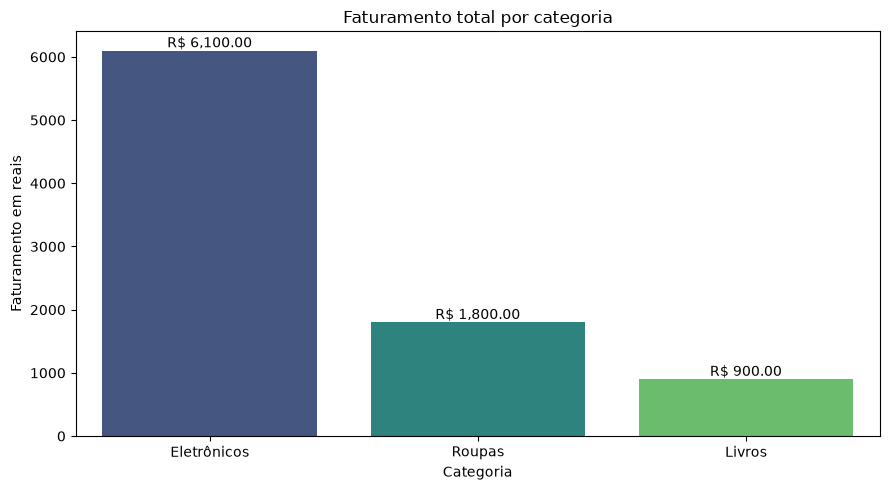

In [32]:
plt.figure(figsize=(9, 5))

grafico1 = sns.barplot(
    data=vendas_por_categoria,
    x="categoria",
    y="faturamento",
    hue="categoria",
    palette="viridis",
    legend=False
)

plt.title("Faturamento total por categoria")
plt.xlabel("Categoria")
plt.ylabel("Faturamento em reais")

for barra in grafico1.patches:
    valor = barra.get_height()

    grafico1.annotate(
        f"R$ {valor:,.2f}",
        (
            barra.get_x() + barra.get_width() / 2,
            valor
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


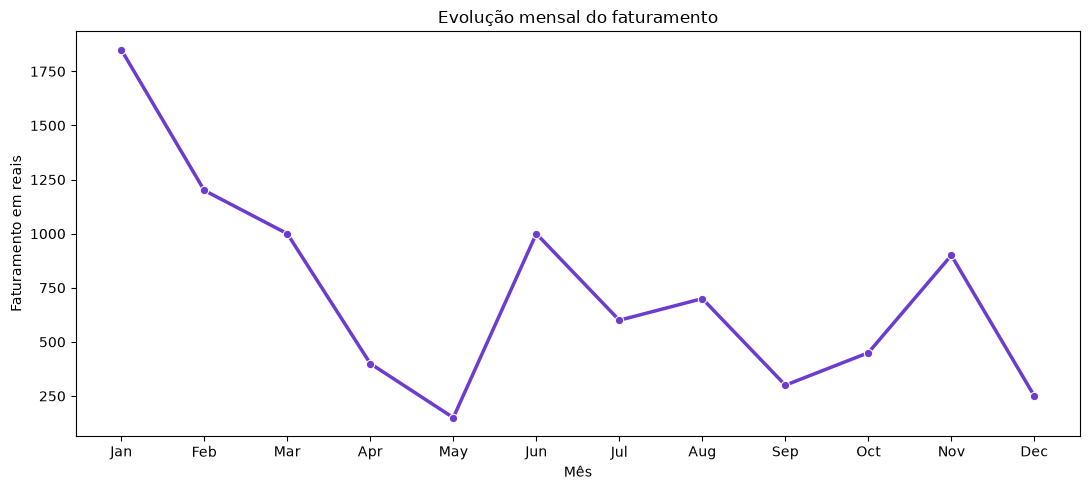

In [33]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=vendas_por_mes,
    x="mes",
    y="valor_venda",
    marker="o",
    linewidth=2.5,
    color="#6C3CCF"
)

plt.title("Evolução mensal do faturamento")
plt.xlabel("Mês")
plt.ylabel("Faturamento em reais")
plt.tight_layout()
plt.show()

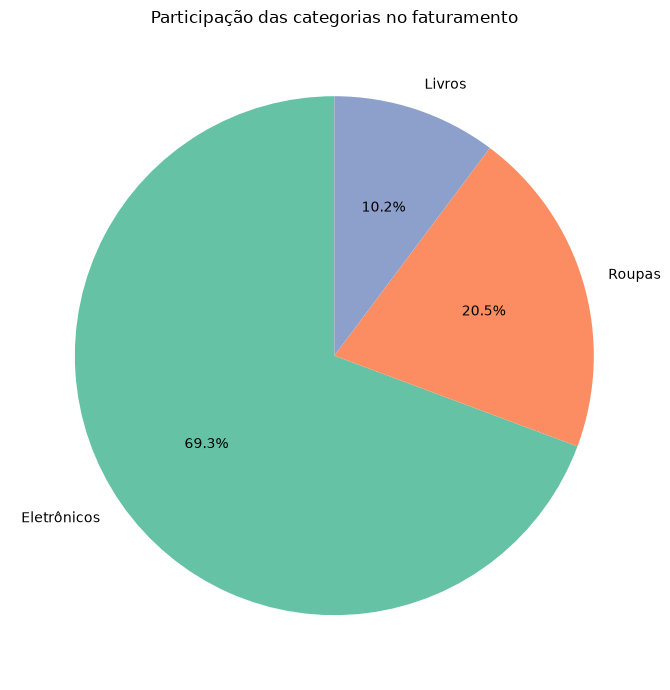

In [34]:
plt.figure(figsize=(7, 7))

plt.pie(
    vendas_por_categoria["faturamento"],
    labels=vendas_por_categoria["categoria"],
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2")
)

plt.title("Participação das categorias no faturamento")
plt.tight_layout()
plt.show()


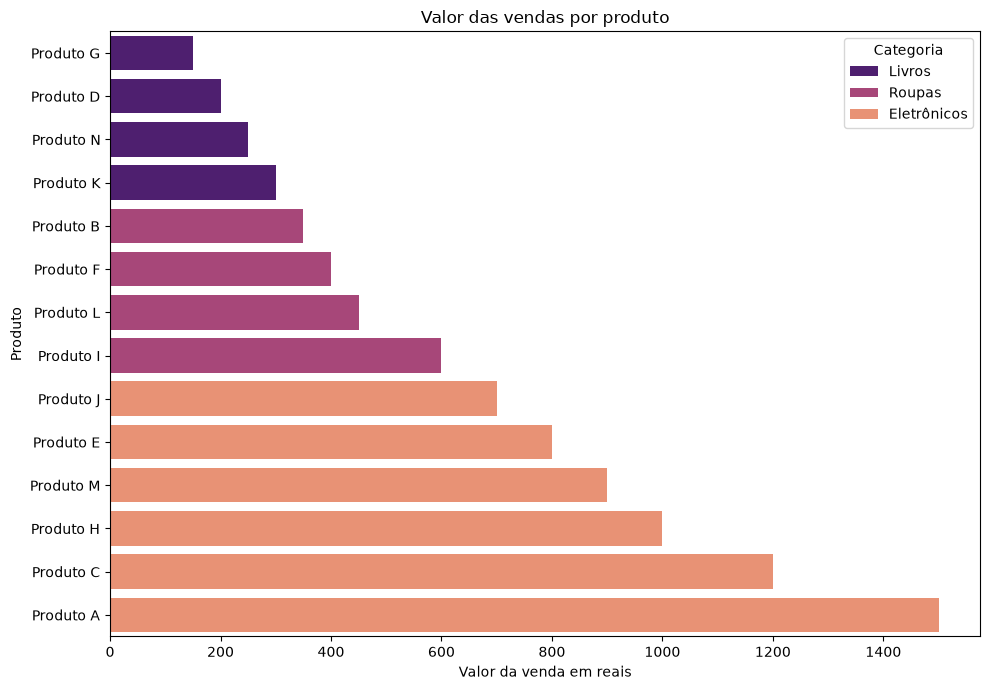

In [35]:
df_produtos = df_vendas.sort_values(
    "valor_venda",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=df_produtos,
    x="valor_venda",
    y="produto",
    hue="categoria",
    palette="magma"
)

plt.title("Valor das vendas por produto")
plt.xlabel("Valor da venda em reais")
plt.ylabel("Produto")
plt.legend(title="Categoria")
plt.tight_layout()
plt.show()

In [36]:
conexao.close()

print("Análise concluída e conexão encerrada!")

Análise concluída e conexão encerrada!


# Análise de Dados de Vendas com Python

Projeto desenvolvido para analisar os dados anuais de vendas de uma empresa de varejo, utilizando Python, SQLite, Pandas, Matplotlib e Seaborn.

**Autora:** Amanda Gomes Damascena

## Conclusão

A análise demonstrou como Python, SQLite e bibliotecas de análise de dados podem transformar registros de vendas em informações úteis para a tomada de decisões. Os resultados indicaram que a categoria Eletrônicos apresentou o maior faturamento e evidenciaram diferenças relevantes entre os valores mensais.